# 🌳 Tree of Thought + Subquestion Decomposition

**Exercise duration: ~20 minutes** | Run every cell top-to-bottom

---

## What You'll Build

| Technique | Idea | What students should notice |
|---|---|---|
| **Tree of Thought (ToT)** | Explore multiple candidate next steps, score them, keep the best | A structured search can produce a stronger plan before final generation |
| **Subquestion Decomposition** | Break one hard problem into smaller answerable pieces | Better structure often improves reliability on multi-step math |
| **Plan-and-Solve** | Sketch a plan before executing | Separating planning from solving reduces messy reasoning |

---

**▶️RUN** = just execute. **🎯TODO** = fill in before running.

> ⚠️ Use a **GPU runtime**, e.g. T4/L4. To change the runtime, go to **Runtime** -> **Change Runtime Type**-> **Choose T4 GPU**

In [ ]:
#@title Install Dependencies {display-mode: "form"}
#@markdown Run this cell to install the required packages.
!pip install -q transformers accelerate datasets
import torch
print(f"\u2705 GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else chr(10)+chr(10)+'  WARNING: No GPU found. Go to Runtime > Change runtime type > T4 GPU.'}")

✅ GPU: Tesla T4


In [ ]:
#@title Load the Model and Tokenizer {display-mode: "form"}
#@markdown Loads **Qwen2.5-0.5B-Instruct** and its tokenizer. This may take a few minutes on the first run.
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
print(f"Loading {MODEL_ID} ...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,   # half-precision: 2x faster, half the VRAM
    device_map="auto",           # auto-selects GPU
)
model.eval()
print(f"Model loaded on {next(model.parameters()).device}")

Loading Qwen/Qwen2.5-0.5B-Instruct ...


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded on cuda:0


In [ ]:
#@title Utility and Helper Functions {display-mode: "form"}
#@markdown Helper functions to generate model response and display results.
import re
import uuid, time, html as html_lib
from IPython.display import display, HTML


def clean_model_text(text: str) -> str:
    if text is None:
        return ""
    t = str(text).strip()

    # Unwrap common LaTeX answer wrappers.
    # Examples: "\\boxed{42}", "$\\boxed{42}$", "boxed{42}", "$42$", "\\(42\\)", "\\[42\\]".
    t = re.sub(r"\$?\\\\boxed\{([^}]*)\}\$?", r"\1", t)
    t = re.sub(r"\$?boxed\{([^}]*)\}\$?", r"\1", t)

    m = re.fullmatch(r"\$([^$]+)\$", t)
    if m:
        t = m.group(1).strip()

    m = re.fullmatch(r"\\\((.*)\\\)", t)
    if m:
        t = m.group(1).strip()

    m = re.fullmatch(r"\\\[(.*)\\\]", t)
    if m:
        t = m.group(1).strip()

    return t


def generate_response(messages, max_new_tokens=None, creative=False):
    """Send chat-formatted messages to the model and return the response."""
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    ).to(model.device)

    gen_kwargs = dict(
        do_sample=creative,
        temperature=0.7 if creative else 1.0,
        pad_token_id=tokenizer.eos_token_id,
    )
    if max_new_tokens is not None:
        gen_kwargs["max_new_tokens"] = max_new_tokens

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            **gen_kwargs,
        )

    response = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[-1]:],
        skip_special_tokens=True,
    )
    return clean_model_text(response)


def display_sample(question, answer):
    display(HTML(
        f"<p><strong>Question:</strong> {question}</p>"
        f"<p><strong>Answer:</strong> {answer}</p>"
    ))


def display_response(prompt_text, response_text, elapsed=None):
    uid = str(uuid.uuid4()).replace("-", "")
    time_tag = f"<div style='color:#666;font-size:90%;margin-top:4px'>&#x23F1; {elapsed:.1f}s</div>" if elapsed else ""
    safe_p = html_lib.escape(str(prompt_text).strip())
    safe_r = html_lib.escape(clean_model_text(str(response_text))).strip()
    display(HTML(
        "<style>.rt{border-collapse:collapse;width:100%;margin:10px 0;font-family:'Segoe UI',sans-serif;font-size:14px}"
        ".rt th,.rt td{border:1px solid #ddd;padding:9px 12px;vertical-align:top}"
        ".rt th{background:#f5f5f5;width:120px;font-weight:600}"
        "pre.rm{white-space:pre-wrap;margin:0}</style>"
        f"<table class='rt'>"
        f"<tr><th>Prompt</th><td><pre class='rm'>{safe_p}</pre></td></tr>"
        f"<tr><th>Response</th><td><pre class='rm'>{safe_r}</pre>{time_tag}</td></tr>"
        "</table>"
    ))


def run_and_display(messages, max_new_tokens=None, creative=False):
    """Generate and display in a table. Returns the response string."""
    prompt_text = messages[-1]["content"]
    t0 = time.time()
    response = generate_response(messages, max_new_tokens=max_new_tokens, creative=creative)
    elapsed = time.time() - t0
    display_response(prompt_text, response, elapsed)
    return response

## 🌳 Part 1: Tree of Thought (ToT)

### What's different about Tree of Thought?

Standard Chain of Thought forces the model down a **single reasoning path**. But what if the first step it takes is suboptimal?

**Tree of Thought** lets the model branch out 🌳. This is what it does:

1. Start with an empty outline
2. Generate **multiple candidate next outline lines**
3. Score them
4. Keep only the best **beams**
5. Repeat for a few steps
6. Use the best outline to write the final story

So your task here is:

> **First build a short outline through search, then write the story from the best outline.**

That is the whole point of ToT: **don't commit too early**. It's essentially **beam search applied to reasoning**.

Think of it like brainstorming: instead of committing to the first idea, you generate several options, compare them, and develop the most promising one.

Each section below walks through one stage of this process — from setup 🛠️ to proposal 💡 to final composition.

### Step 1: Configuration & Prompt Templates

**▶️RUN** We define two key parameters:
- **B** (branching factor): how many candidate ideas to generate at each step
- **D** (depth): how many reasoning steps to take

🧮 Wider B → more ideas explored; deeper D → longer reasoning chains.

In [ ]:
from typing import List, Tuple, Dict
import random
random.seed(42)

B = 3   # keep top 3 beams after each step
D = 2   # build a 2-line outline before composing the story

**▶️RUN** Define the prompt templates. Notice the `{placeholders}`.

In [ ]:
TASK_INSTRUCTION = (
    "Write a vivid short story of about 100 words for a general audience. "
    "It must include: (1) strong imagery, (2) a surprising twist, and (3) an emotionally satisfying ending. "
    "Do not use proper names."
)

PROPOSE_PROMPT = """
You are planning a short story.

Story brief:
{task}

Current outline:
{outline}

Write exactly ONE good next outline line for the story.
It should move the story forward in a concrete way.
Return ONLY that one line.
""".strip()

SCORE_PROMPT = """
You are evaluating one candidate outline line for a short story.

Story brief:
{task}

Current outline:
{outline}

Candidate next line:
{candidate}

Give one integer score from 0 to 10 based on:
- fit with the brief
- coherence with the current outline
- creativity / story potential

Return ONLY the integer.
""".strip()

### Quick Python check: `.format()` fills placeholders

**▶️RUN**

In [ ]:
# How .format() fills placeholders:
prompt = PROPOSE_PROMPT.format(task=TASK_INSTRUCTION, outline="(none yet)")
print(prompt)

You are planning a short story.

Story brief:
Write a vivid short story of about 100 words for a general audience. It must include: (1) strong imagery, (2) a surprising twist, and (3) an emotionally satisfying ending. Do not use proper names.

Current outline:
(none yet)

Write exactly ONE good next outline line for the story.
It should move the story forward in a concrete way.
Return ONLY that one line.


### Try it for the scoring template

`SCORE_PROMPT` has **three** placeholders: `{task}`, `{outline}`, `{candidate}`.

This is exactly how the tree gets generated:
- the current outline is inserted into the prompt,
- the model proposes the **next** line,
- then that candidate line is scored.

In [ ]:
# your code here
prompt = SCORE_PROMPT.format(
    task=TASK_INSTRUCTION,
    outline="(none yet)",
    candidate="A lonely keeper finds a mysterious bottle."
)
print(prompt)

You are evaluating one candidate outline line for a short story.

Story brief:
Write a vivid short story of about 100 words for a general audience. It must include: (1) strong imagery, (2) a surprising twist, and (3) an emotionally satisfying ending. Do not use proper names.

Current outline:
(none yet)

Candidate next line:
A lonely keeper finds a mysterious bottle.

Give one integer score from 0 to 10 based on:
- fit with the brief
- coherence with the current outline
- creativity / story potential

Return ONLY the integer.


Good. You'll use this `.format()` pattern in every exercise below.

### Step 2: ToT Core Functions (propose → score)

**[IMPORTANT]** Before running the next cell, read this note on **Chat Templates**:

When using a modern instruction-tuned model like Qwen, you don't just send a raw string. Instead, messages are formatted as a list of dictionaries, each with:
- **`role`**: either `"user"` or `"assistant"`
- **`content`**: the actual text

```python
message = [{"role": "user", "content": "Your prompt here"}]
```

This format is called the **Chat Template** and it's how the model knows who is speaking.


**Speed tip built into `generate_response`:**
- `creative=False` → greedy, fastest. Use for scoring (just need an integer).
- `creative=True` → sampled. Use for story generation.

Below, the tree is generated very simply:

- `propose_next_beams(...)` makes **`b` separate model calls** to get `b` different candidate next lines
- `score_beams(...)` scores each candidate
- later, beam search keeps only the best few

This makes the search visible and easy to explain in class.

### **🎯TODO** Implement `score_candidates`

In `score_beams`: build the prompt using `SCORE_PROMPT` template, create the message dict, and call the model.

In [ ]:
def propose_next_beams(outline_lines, b):
    """Generate b candidate next outline lines for the current partial outline."""
    outline_text = "\n".join(f"- {line}" for line in outline_lines) if outline_lines else "(empty outline)"
    prompt = PROPOSE_PROMPT.format(task=TASK_INSTRUCTION, outline=outline_text)
    message = [{"role": "user", "content": prompt}]

    candidates = []
    for _ in range(b):
        #🎯TODO: Fill in the generate_response function.
        #💡TIP: Set maximum number of tokens to 60 and creative variable to True
        response = generate_response(message, max_new_tokens=60, creative=True)
        response = clean_model_text(response).split("\n")[0].strip("-• ").strip()
        if response and response not in candidates:
            candidates.append(response)

    return candidates


def score_beams(outline_lines, candidates):
    """Score each candidate next line. Returns list of (candidate, score)."""
    scored = []
    outline_text = "\n".join(f"- {line}" for line in outline_lines) if outline_lines else "(empty outline)"

    for candidate in candidates:
        #🎯TODO: Complete the score_prompt as defined above
        prompt = SCORE_PROMPT.format(
            task=TASK_INSTRUCTION,
            outline=outline_text,
            candidate=candidate,
        )
        message = [{"role": "user", "content": prompt}]
        try:
            resp = generate_response(message, max_new_tokens=6, creative=False)
            m = re.search(r"\d+", resp)
            score = float(m.group()) if m else 0.0
            score = max(0.0, min(10.0, score))
        except Exception:
            score = 0.0

        scored.append((candidate, score))

    return scored

### 🎯TODO Step 3: Beam Search over Outline Steps

This is the core of the Tree-of-Thought algorithm 🌳. It loops through reasoning steps at every depth:

1. **Propose** candidate thoughts using `propose_next_beams`
2. **Score & select** the top `B` outlines using `score_beams`
3. **Expand** further until the outline is complete

Your task: fill in the two `TODO` lines to call the right functions.

In [ ]:
def beam_search_outline(b=B, d=D):
    """
    Tree-of-Thought beam search over short story outlines.

    Beam state:
        {
            "outline": [...],
            "avg_score": float
        }
    """
    beams = [{"outline": [], "avg_score": 0.0}]
    history = []

    for step in range(1, d + 1):
        expanded = []

        for beam in beams:
            outline = beam["outline"]
            #🎯TODO : call the appropriate functions to define the candidates
            #and their score
            candidates = propose_next_beams(outline, b=b)
            scored = score_beams(outline, candidates)

            for candidate, score in scored:
                new_outline = outline + [candidate]
                new_avg = (beam["avg_score"] * (step - 1) + score) / step
                expanded.append({
                    "outline": new_outline,
                    "avg_score": new_avg,
                    "new_line": candidate,
                    "step_score": score,
                    "parent_outline": outline,
                })

        expanded.sort(key=lambda x: x["avg_score"], reverse=True)
        kept = expanded[:b]

        history.append({
            "step": step,
            "expanded": expanded,
            "kept": kept,
        })

        print(f"Step {step}: explored {len(expanded)} candidates, kept top {len(kept)} beams")
        for rank, beam in enumerate(kept, 1):
            print(f"  #{rank} | avg={beam['avg_score']:.1f} | added: {beam['new_line']}")

        beams = [{"outline": beam["outline"], "avg_score": beam["avg_score"]} for beam in kept]

    return beams[0]["outline"], history

### Step 4: Compose the Final Story

Now we use the **best outline found by search** and ask the model to write the final story from it.

That makes the workflow explicit:

**search first → generate final answer second**



In [ ]:
COMPOSE_PROMPT = """
Using the outline below, write the final story in about 100 words.

Story brief:
{task}

Outline:
{beats}

Write one polished paragraph.
""".strip()

def compose_story(beams):
    beats_text = "\n".join(f"- {b}" for b in beams)
    prompt = COMPOSE_PROMPT.format(task=TASK_INSTRUCTION, beats=beats_text)
    message = [{"role": "user", "content": prompt}]
    return run_and_display(message, max_new_tokens=180, creative=True)

### Step 5: Run the Full ToT Pipeline

This cell now shows:
- how the outline starts from an **empty** state,
- which candidates were explored,
- which beams survived,
- and the final story written from the best outline.

In [ ]:
print("Running Tree-of-Thought outline search...\n")
best_beams, tot_history = beam_search_outline(b=B, d=D)

print("\nBest outline selected by search:")
for i, line in enumerate(best_beams, 1):
    print(f"  {i}. {line}")

print("\nComposing final story from the best outline...\n")
tot_story = compose_story(best_beams)

Running Tree-of-Thought outline search...

Step 1: explored 3 candidates, kept top 3 beams
  #1 | avg=8.0 | added: "Once upon a time, in a small village nestled among the mountains, there lived a young girl named Lily. She was known for her kindness and love for nature. One day, while wandering through the forest, she stumbled upon a hidden cave filled with strange artifacts."
  #2 | avg=8.0 | added: "Once upon a time, in a bustling city far away, there was a young woman named Eliza who dreamed of exploring the world's most mysterious cave system. She had heard tales of ancient treasures hidden within its depths, but she knew it would take courage to venture into the unknown."
  #3 | avg=8.0 | added: "Once upon a time, in a small village nestled between rolling hills, there lived a young girl named Lily who dreamed of exploring the world far beyond her hometown. One day, while wandering through the dense forests, she stumbled upon a hidden cave system that seemed to hold secrets waitin

Prompt,"Using the outline below, write the final story in about 100 words. Story brief: Write a vivid short story of about 100 words for a general audience. It must include: (1) strong imagery, (2) a surprising twist, and (3) an emotionally satisfying ending. Do not use proper names. Outline: - ""Once upon a time, in a small village nestled among the mountains, there lived a young girl named Lily. She was known for her kindness and love for nature. One day, while wandering through the forest, she stumbled upon a hidden cave filled with strange artifacts."" - ""Upon entering the cave, Lily felt an inexplicable pull towards something ancient and ethereal."" Write one polished paragraph."
Response,"Once upon a time, in a small village nestled among the mountains, there lived a young girl named Lily. She was known for her kindness and love for nature. One day, while wandering through the forest, she stumbled upon a hidden cave filled with strange artifacts. Upon entering the cave, Lily felt an inexplicable pull towards something ancient and ethereal. As she explored deeper into the cave, she discovered that the artifacts were connected to a mysterious force that had been dormant for centuries. With newfound power, Lily was able to manipulate the elements around her, creating a beautiful rainbow in the sky. From that day on, Lily became known as a legend in the village, inspiring awe and wonder in those who saw her magic.⏱ 5.9s"


### Baseline: Direct Story (No ToT)

**▶️RUN** Same story task, but this time the model writes immediately.

Now students can compare:

- **Direct generation**: one shot
- **ToT generation**: search over multiple candidate outline paths first

In [ ]:
BASELINE_PROMPT = """
{task}

Write the story now in about 100 words as one polished paragraph.
""".strip()

print("Zero-shot baseline (no Tree of Thought)...\n")
baseline_prompt = BASELINE_PROMPT.format(task=TASK_INSTRUCTION)
baseline_story = run_and_display([{"role": "user", "content": baseline_prompt}], max_new_tokens=180, creative=True)

Zero-shot baseline (no Tree of Thought)...



Prompt,"Write a vivid short story of about 100 words for a general audience. It must include: (1) strong imagery, (2) a surprising twist, and (3) an emotionally satisfying ending. Do not use proper names. Write the story now in about 100 words as one polished paragraph."
Response,"In a world where dreams are made from sand and laughter is exchanged with the wind, there lived a young girl named Elara who dreamed of soaring high above the bustling city of Zephyria. She dreamt of flying through the sky, of soaring to heights beyond her wildest imaginings. But when she finally flew high enough to reach the top of the city's tallest tower, she was met with a harsh reality that would change everything. The tower, once a beacon of hope and freedom, now stood cold and empty. The air was thick with dust and smog, and the people who used to walk on its steps were now stuck in their cars or buses, unable to leave the city. Elara could see the city's streets filled with empty buildings, their windows blanketed by glass, and the sounds of traffic drowned out by the constant hum of engines. As she began to explore⏱ 6.5s"


### Optional: Quick side-by-side quality check

The same model can act as a **rough judge** here.
That is not a rigorous benchmark, but it helps make the classroom point visible:

- the baseline writes immediately,
- ToT first searches over several outline paths,
- then writes from the strongest outline.

In [ ]:
JUDGE_PROMPT = """
You are comparing two short stories written for the same brief.

Brief:
{task}

Story A:
{story_a}

Story B:
{story_b}

For each story, give an integer 0-10 for:
- imagery
- twist quality
- satisfying ending
- overall fit to the brief

Then say which story is better overall.

Use this exact format:
A: <score>
B: <score>
""".strip()

judge_text = run_and_display(
    [{"role": "user", "content": JUDGE_PROMPT.format(
        task=TASK_INSTRUCTION,
        story_a=baseline_story,
        story_b=tot_story
    )}],
    max_new_tokens=120,
    creative=False
)

print("Interpretation:")
print("A = direct baseline, B = Tree-of-Thought story")

Prompt,"You are comparing two short stories written for the same brief. Brief: Write a vivid short story of about 100 words for a general audience. It must include: (1) strong imagery, (2) a surprising twist, and (3) an emotionally satisfying ending. Do not use proper names. Story A: In a world where dreams are made from sand and laughter is exchanged with the wind, there lived a young girl named Elara who dreamed of soaring high above the bustling city of Zephyria. She dreamt of flying through the sky, of soaring to heights beyond her wildest imaginings. But when she finally flew high enough to reach the top of the city's tallest tower, she was met with a harsh reality that would change everything. The tower, once a beacon of hope and freedom, now stood cold and empty. The air was thick with dust and smog, and the people who used to walk on its steps were now stuck in their cars or buses, unable to leave the city. Elara could see the city's streets filled with empty buildings, their windows blanketed by glass, and the sounds of traffic drowned out by the constant hum of engines. As she began to explore Story B: Once upon a time, in a small village nestled among the mountains, there lived a young girl named Lily. She was known for her kindness and love for nature. One day, while wandering through the forest, she stumbled upon a hidden cave filled with strange artifacts. Upon entering the cave, Lily felt an inexplicable pull towards something ancient and ethereal. As she explored deeper into the cave, she discovered that the artifacts were connected to a mysterious force that had been dormant for centuries. With newfound power, Lily was able to manipulate the elements around her, creating a beautiful rainbow in the sky. From that day on, Lily became known as a legend in the village, inspiring awe and wonder in those who saw her magic. For each story, give an integer 0-10 for: - imagery - twist quality - satisfying ending - overall fit to the brief Then say which story is better overall. Use this exact format: A: <score> B: <score>"
Response,"A: 8 B: 9 A: 8 B: 9 Both stories have strong imagery, but Story A has a more vivid description of the city skyline and the people walking on the steps, making it more engaging. However, Story B has a more imaginative and fantastical setting, which adds depth to the narrative. Overall, both stories are well-written and create interesting characters and plot twists. Therefore, I would recommend both stories equally.⏱ 3.7s"


Interpretation:
A = direct baseline, B = Tree-of-Thought story


---

## 🧠 Part 2: Subquestion Decomposition

### The big idea

Sometimes a problem is just too complex to solve in one shot 🧠💥. Instead of attacking it head-on, we break it into smaller, focused sub-questions — each one answerable on its own — and combine the answers at the end.

This mimics how humans tackle hard problems: **think → split → solve → combine** 🔄

We'll test this on the **GSM8K socratic split**, which includes worked examples with explicit subquestion breakdowns.

Furthermore, we compare **direct solving** vs **subquestion decomposition** in a much neater way.

In [ ]:
#@title Load the Socratic GSM8K Split {display-mode: "form"}
#@markdown Loads the socratic version of GSM8K, where each answer is broken into guided sub-questions.
ds_socratic = load_dataset("openai/gsm8k", "socratic")
train_split_socratic = ds_socratic["train"]
test_split_socratic  = ds_socratic["test"]

print(f"Train: {len(train_split_socratic)} | Test: {len(test_split_socratic)}")


README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

socratic/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.68MB            

socratic/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

socratic/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  487kB            

socratic/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

Train: 7473 | Test: 1319


In [ ]:
#@title Explore a Socratic Sample {display-mode: "form"}
#@markdown Displays the first question-answer pair from the socratic training split.

display_sample(train_split_socratic[0]["question"], train_split_socratic[0]["answer"])

In [ ]:
#@title Utility functions {display-mode: "form"}
#@markdown Functions to extract only the numerical answers from the true values and predictions

def extract_gold_answer(answer_text):
    parts = str(answer_text).split("####")
    return parts[-1].strip() if len(parts) > 1 else answer_text.strip()

def extract_pred_answer(text):
    text = clean_model_text(text)
    patterns = [
        r"Final answer\s*[:\-]\s*([^\n]+)",
        r"Answer\s*[:\-]\s*([^\n]+)",
        r"Therefore[^\n]*?([\$]?[\d,]+(?:\.\d+)?)",
        r"([\$]?[\d,]+(?:\.\d+)?)\s*$",
    ]
    for pattern in patterns:
        m = re.search(pattern, text, flags=re.IGNORECASE)
        if m:
            return m.group(1).strip().replace(",", "")
    return text.strip().split("\n")[-1].strip()

### 🎯 TODO Build two prompts for the same question

We will compare:

- **DIRECT_PROMPT**: solve the problem in one go
- **SUBQUESTION_PROMPT**: explicitly break it into a few small questions first

Draft these 2 prompts below such that the model can efficiently follow this strategy.

In [ ]:
#🎯 TODO: Define your prompt here:
DIRECT_PROMPT = """
Solve the following math word problem carefully.
Show brief reasoning and end with:
Final answer: <number>

Question: {question}
""".strip()


#🎯 TODO: Define your prompt here:
SUBQUESTION_PROMPT = """
Solve the following math word problem by breaking it into a few useful subquestions.

Rules:
- Write 2 to 4 subquestions only
- Each subquestion should help compute one needed quantity
- Answer each subquestion briefly
- End with exactly: Final answer: <number>

Question: {question}
""".strip()

In [ ]:
#@title Comparison functions {display-mode: "form"}
#@markdown Functions to compare the Direct and Subquestion prompts
def run_prompt(prompt_text, max_new_tokens=256):
    return generate_response([{"role": "user", "content": prompt_text}], max_new_tokens=max_new_tokens, creative=False)

def compare_on_example(example_idx=0):
    item = test_split_socratic[example_idx]
    question = item["question"]
    gold = extract_gold_answer(item["answer"])

    direct_text = run_prompt(DIRECT_PROMPT.format(question=question))
    subq_text = run_prompt(SUBQUESTION_PROMPT.format(question=question))

    direct_pred = extract_pred_answer(direct_text)
    subq_pred = extract_pred_answer(subq_text)

    display(HTML(
        f"<h4>Question</h4><p>{html_lib.escape(question)}</p>"
        f"<p><strong>Gold answer:</strong> {html_lib.escape(gold)}</p>"
    ))

    display_response("Direct baseline prompt", direct_text)
    display_response("Subquestion decomposition prompt", subq_text)

    return {
        "question": question,
        "gold": gold,
        "direct_pred": direct_pred,
        "subq_pred": subq_pred,
        "direct_correct": direct_pred == gold,
        "subq_correct": subq_pred == gold,
    }

### Example comparison on one test problem

**▶️RUN** Start with one problem so students can inspect the two outputs side by side.

In [ ]:
#@title Run the comparison {display-mode: "form"}
#@markdown Call the function to compare the approaches on one data sample

subq_example_result = compare_on_example(example_idx=3)

Prompt,Direct baseline prompt
Response,"To solve this problem, we need to calculate the total distance James runs in one week. 1. First, let's determine how many sprints James runs in one week: - James runs 3 sprints per day. - There are 7 days in a week. - Therefore, the number of sprints he runs in one week is \(3 \times 7 = 21\). 2. Next, we know that each sprint is 60 meters long. - So, the total distance James runs in one week is \(21 \times 60\) meters. Let's perform the multiplication: \[ 21 \times 60 = 1260 \] Therefore, the total distance James runs in one week is **1260 meters**. Final answer: 1260 meters"


Prompt,Subquestion decomposition prompt
Response,"1. **Calculate the distance James runs in one session:** - James runs 60 meters per sprint. - He runs 3 sprints per session. - Therefore, the distance for one session is \( 60 \text{ meters/sprint} \times 3 \text{ sprints/week} = 180 \text{ meters/week} \). 2. **Calculate the total distance James runs in a week:** - James runs 3 sessions per week. - The distance for one session is 180 meters. - Therefore, the total distance for the week is \( 180 \text{ meters/session} \times 3 \text{ sessions/week} = 540 \text{ meters/week} \). Final answer: James runs a total of 540 meters a week."


### Small mini-benchmark (3 problems)

One example can be noisy.  
So let's compare both strategies on a tiny set of 3 test problems and summarize the results in a table.

In [ ]:
sample_indices = [1, 3, 10] #feel free to choose any other indices. There are 7473 samples in train and 1319 in test set
rows = []

for idx in sample_indices:
    result = compare_on_example(example_idx=idx)
    rows.append(result)

direct_acc = sum(r["direct_correct"] for r in rows)
subq_acc = sum(r["subq_correct"] for r in rows)

summary_rows = []
for i, r in zip(sample_indices, rows):
    summary_rows.append(
        f"<tr><td>{i}</td>"
        f"<td>{'✅' if r['direct_correct'] else '❌'}</td>"
        f"<td>{'✅' if r['subq_correct'] else '❌'}</td>"
        f"<td>{html_lib.escape(r['gold'])}</td></tr>"
    )

Prompt,Direct baseline prompt
Response,"To solve this problem, let's break down the information given: 1. A robe requires 2 bolts of blue fiber. 2. The amount of white fiber required is half that of blue fiber. First, we need to find out how much white fiber is needed for one bolt of blue fiber: - Since 2 bolts of blue fiber require 2 bolts of white fiber, - Therefore, 1 bolt of blue fiber requires \( \frac{2}{2} = 1 \) bolt of white fiber. Now, we can calculate the total number of bolts needed for both types of fibers: - For blue fiber: 2 bolts - For white fiber: 1 bolt Total bolts = Blue fiber bolts + White fiber bolts Total bolts = 2 + 1 Total bolts = 3 Therefore, the final answer is: 3."


Prompt,Subquestion decomposition prompt
Response,"1. **Subquestion 1:** How many bolts of blue fiber are there? - Since it takes 2 bolts of blue fiber, we need to multiply this number by itself. - Calculation: \( 2 \times 2 = 4 \) bolts 2. **Subquestion 2:** How many bolts of white fiber are there? - It takes half as much white fiber as blue fiber, so we divide the number of blue fibers by 2. - Calculation: \( 4 \div 2 = 2 \) bolts 3. **Subquestion 3:** Total number of bolts (blue + white): - We add the number of blue bolts and white bolts together. - Calculation: \( 4 + 2 = 6 \) bolts Final answer: The total number of bolts is 6."


Prompt,Direct baseline prompt
Response,"To solve this problem, we need to calculate the total distance James runs in one week. 1. First, let's determine how many sprints James runs in one week: - James runs 3 sprints per day. - There are 7 days in a week. - Therefore, the number of sprints he runs in one week is \(3 \times 7 = 21\). 2. Next, we know that each sprint is 60 meters long. - So, the total distance James runs in one week is \(21 \times 60\) meters. Let's perform the multiplication: \[ 21 \times 60 = 1260 \] Therefore, the total distance James runs in one week is **1260 meters**. Final answer: 1260 meters"


Prompt,Subquestion decomposition prompt
Response,"1. **Calculate the distance James runs in one session:** - James runs 60 meters per sprint. - He runs 3 sprints per session. - Therefore, the distance for one session is \( 60 \text{ meters/sprint} \times 3 \text{ sprints/week} = 180 \text{ meters/week} \). 2. **Calculate the total distance James runs in a week:** - James runs 3 sessions per week. - The distance for one session is 180 meters. - Therefore, the total distance for the week is \( 180 \text{ meters/session} \times 3 \text{ sessions/week} = 540 \text{ meters/week} \). Final answer: James runs a total of 540 meters a week."


Prompt,Direct baseline prompt
Response,"To solve this problem, we need to calculate the downloads for each month and then sum them up. 1. **First Month Downloads**: The program had 60 downloads. 2. **Second Month Downloads**: The number of downloads in the second month is three times the downloads in the first month. So, \(3 \times 60 = 180\) downloads. 3. **Third Month Downloads**: The downloads in the third month were reduced by 30%. To find out how many downloads that would be, we calculate 70% (or 0.7) of the downloads from the second month. So, \(180 \times 0.7 = 126\) downloads. Now, let's add up all the downloads: - First month: 60 downloads - Second month: 180 downloads - Third month: 126 downloads Total downloads = 60 + 180 + 126 = 366 downloads Therefore, the final answer is: 366."


Prompt,Subquestion decomposition prompt
Response,Sure! Let's break down the problem step-by-step and solve it using Python code for accuracy. ### Subquestions: 1. **First Month Downloads:** - We know that the program had 60 downloads in the first month. 2. **Second Month Downloads:** - The number of downloads in the second month is three times the downloads in the first month. - Calculation: \( \text{Downloads in Second Month} = 3 \times 60 \) 3. **Third Month Downloads:** - The downloads in the third month were reduced by 30% from the downloads in the second month. - Calculation: \( \text{Downloads in Third Month} = \text{Downloads in Second Month} \times (1 - 0.3) \) Let's calculate these values using Python code. ```python # First month downloads first_month_downloads = 60 # Calculating downloads in the second month second_month_downloads = 3 * first_month_downloads # Calculating downloads in the third month after reducing by 30% third_month_downloads = second_month_downloads * (1 - 0.3) # Total downloads over the three months


## Prompt evaluation
In the next steps, we extract 20 questions from the dataset and evaluate the model's response using the following prompts:

**1.Normal prompt**

**2.Subquestion prompt**

**3.CoT prompt**

In [ ]:
# @title Generate response in batches

import torch

def generate_response_batch(messages_batch, max_new_tokens=256):
    """Generate responses for a batch of chat conversations."""

    # Format each conversation using the model's chat template.
    formatted_prompts = [
        tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )
        for messages in messages_batch
    ]

    # Left padding is recommended for batched decoder-only generation.
    old_padding_side = tokenizer.padding_side
    tokenizer.padding_side = "left"

    try:
        if tokenizer.pad_token_id is None:
            tokenizer.pad_token = tokenizer.eos_token

        inputs = tokenizer(
            formatted_prompts,
            padding=True,
            return_tensors="pt",
        ).to(model.device)
    finally:
        tokenizer.padding_side = old_padding_side

    # All prompts now have the same padded input length.
    input_length = inputs["input_ids"].shape[1]

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
        )

    # Remove the padded input tokens and decode each generated response.
    generated_tokens = outputs[:, input_length:]

    responses = tokenizer.batch_decode(
        generated_tokens,
        skip_special_tokens=True,
    )

    return [clean_model_text(response) for response in responses]

In [ ]:
# @title Helper function to extract the prediction
import re

def extract_gsm8k_prediction(response):
    # Prefer an explicitly labelled final answer.
    patterns = [
        r"final answer\s*:\s*\$?\s*([-+]?\d[\d,]*(?:\.\d+)?)",
        r"####\s*\$?\s*([-+]?\d[\d,]*(?:\.\d+)?)",
    ]

    for pattern in patterns:
        matches = re.findall(pattern, response, re.IGNORECASE)
        if matches:
            return matches[-1].replace(",", "")

    # Fallback: extract the last number in the response.
    numbers = re.findall(
        r"(?<![\w.])-?\d[\d,]*(?:\.\d+)?",
        response
    )
    return numbers[-1].replace(",", "") if numbers else None

In [ ]:
# @title Evaluation loop

import random
import pandas as pd
import re
import time

COT_PROMPT = """
Solve the math word problem step by step.
Show the calculations needed to reach the answer.
End with exactly: Final answer: <number>

Question: {question}
""".strip()

prompts = {
    "Normal": DIRECT_PROMPT,
    "Subquestion": SUBQUESTION_PROMPT,
    "CoT": COT_PROMPT,
}

N_EXAMPLES = 30
BATCH_SIZE = 5
MAX_NEW_TOKENS = 256

random.seed(42)
sample_indices = random.sample(
    range(len(test_split_socratic)),
    min(N_EXAMPLES, len(test_split_socratic)),
)

results = []

for strategy, template in prompts.items():
    print(f"\nEvaluating {strategy} prompting...")
    start_time = time.perf_counter()

    # Process the same examples in batches.
    for start in range(0, len(sample_indices), BATCH_SIZE):
        batch_indices = sample_indices[start:start + BATCH_SIZE]

        batch_items = [
            test_split_socratic[idx] for idx in batch_indices
        ]

        messages_batch = [
            [{
                "role": "user",
                "content": template.format(question=item["question"]),
            }]
            for item in batch_items
        ]

        responses = generate_response_batch(
            messages_batch,
            max_new_tokens=MAX_NEW_TOKENS,
        )

        for idx, item, response in zip(
            batch_indices, batch_items, responses
        ):
            predicted = extract_gsm8k_prediction(response)
            gold = extract_gold_answer(item["answer"])

            correct = (
                    predicted is not None
                    and extract_gsm8k_prediction(str(gold)) == predicted)

            # Normalize common numeric formatting differences.
            def normalize_answer(answer):
                answer = str(answer).strip().replace(",", "")
                answer = re.sub(r"^\$", "", answer)
                answer = re.sub(r"\s+", "", answer)
                return answer

            correct = (
                normalize_answer(predicted)
                == normalize_answer(gold)
            )

            results.append({
                "index": idx,
                "strategy": strategy,
                "question": item["question"],
                "gold_answer": gold,
                "predicted_answer": predicted,
                "correct": int(correct),
                "response": response,
            })

        print(
            f"  Processed {min(start + BATCH_SIZE, len(sample_indices))}"
            f"/{len(sample_indices)}"
        )

    print(f"Time: {time.perf_counter() - start_time:.1f} seconds")

results_df = pd.DataFrame(results)
print("\nEvaluation complete.")


Evaluating Normal prompting...
  Processed 5/30
  Processed 10/30
  Processed 15/30
  Processed 20/30
  Processed 25/30
  Processed 30/30
Time: 73.9 seconds

Evaluating Subquestion prompting...
  Processed 5/30
  Processed 10/30
  Processed 15/30
  Processed 20/30
  Processed 25/30
  Processed 30/30
Time: 47.7 seconds

Evaluating CoT prompting...
  Processed 5/30
  Processed 10/30
  Processed 15/30
  Processed 20/30
  Processed 25/30
  Processed 30/30
Time: 56.1 seconds

Evaluation complete.


Next, we evaluate the model's responses using accuracy, which measures the proportion of math problems for which the model produces the correct final numerical answer.

,Correct,Total,Accuracy,Accuracy (%)
strategy,,,,
Normal,11,30,0.37,36.67
Subquestion,8,30,0.27,26.67
CoT,8,30,0.27,26.67


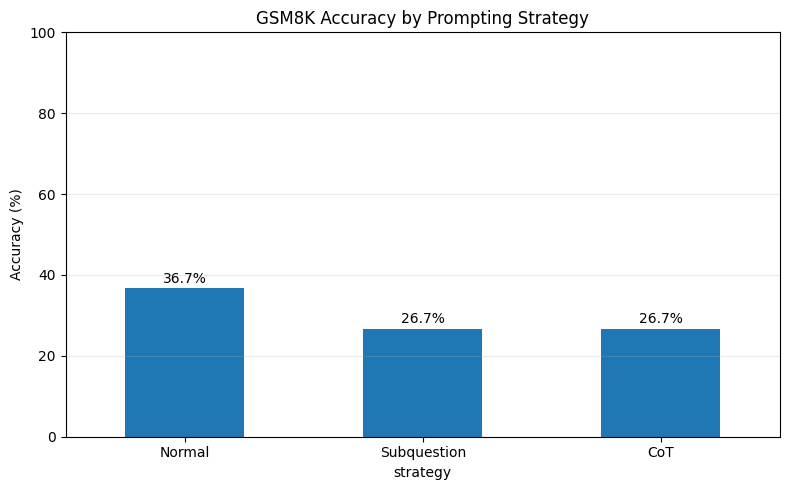

In [ ]:
# @title Prompt Accuracy Visualization

summary = (
    results_df.groupby("strategy")["correct"]
    .agg(["sum", "count", "mean"])
    .reindex(["Normal", "Subquestion", "CoT"])
)

summary.columns = ["Correct", "Total", "Accuracy"]
summary["Accuracy (%)"] = 100 * summary["Accuracy"]

display(summary.round(2))

import matplotlib.pyplot as plt

ax = summary["Accuracy (%)"].plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 100),
    title="GSM8K Accuracy by Prompting Strategy",
    ylabel="Accuracy (%)",
    rot=0,
)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        xytext=(0, 4),
        textcoords="offset points",
    )

ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

The general takeway is that there is no exact prompt srategy that works best but rather it depends on the task we are working on.

---

## 🗺️ Plan-and-Solve Prompting

### What makes this different?

Plan-and-Solve explicitly separates the *planning* phase from the *execution* phase — just like how you'd sketch a rough approach on a whiteboard before diving into code.

**How it works:**
1. **Plan Phase** 🗺️ — The model outlines what steps are needed: "First identify what's asked → then gather given info → compute step by step."
2. **Solve Phase** 🧮 — The model follows its own plan systematically to reach the final answer.


This is similar to subquestioning, but the structure is a **plan**, not a tree of sub-questions. It prevents the model from rushing to compute before it fully understands the problem structure.

In [ ]:
test_q = test_split_socratic[0]["question"]

few_shot_PS = (
    "Follow this format to solve the question:\n\n"
    "Q: James runs 3 sprints 3 times a week, 60 meters each. Total meters per week?\n"
    "A:\n"
    "Given: 3 sprints x 3 times = 9 sprints per week; each sprint is 60 meters.\n"
    "Plan: Multiply total sprints by distance per sprint.\n"
    "Solve: 9 x 60 = 540.\n"
    "Final answer: 540\n\n"
    f"Q: {test_q}\nA:"
)
print(few_shot_PS)
run_and_display([{"role": "user", "content": few_shot_PS}], max_new_tokens=512)

Follow this format to solve the question:

Q: James runs 3 sprints 3 times a week, 60 meters each. Total meters per week?
A:
Given: 3 sprints x 3 times = 9 sprints per week; each sprint is 60 meters.
Plan: Multiply total sprints by distance per sprint.
Solve: 9 x 60 = 540.
Final answer: 540

Q: Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?
A:


Prompt,"Follow this format to solve the question: Q: James runs 3 sprints 3 times a week, 60 meters each. Total meters per week? A: Given: 3 sprints x 3 times = 9 sprints per week; each sprint is 60 meters. Plan: Multiply total sprints by distance per sprint. Solve: 9 x 60 = 540. Final answer: 540 Q: Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market? A:"
Response,"To calculate how much money Janet makes every day from selling the remaining eggs at the farmers' market, we need to follow these steps: 1. Calculate the total number of eggs laid by the ducks in one day. 2. Subtract the number of eggs eaten during breakfast and baked muffins from the total number of eggs. 3. Determine the revenue from selling the remaining eggs. Step 1: Calculate the total number of eggs laid by the ducks in one day. Janet's ducks lay 16 eggs per day. Step 2: Subtract the number of eggs eaten during breakfast and baked muffins from the total number of eggs. - Breakfast: 3 eggs - Baked muffins: 4 eggs Total eggs eaten = 3 + 4 = 7 eggs Step 3: Determine the revenue from selling the remaining eggs. Revenue = Number of eggs sold × Price per egg Revenue = (Total eggs - Eggs eaten) × Price per egg Revenue = (16 - 7) × $2 Revenue = 9 × $2 Revenue = $18 Therefore, Janet makes $18 every day at the farmers' market from selling the remaining eggs.⏱ 9.2s"


"To calculate how much money Janet makes every day from selling the remaining eggs at the farmers' market, we need to follow these steps:\n\n1. Calculate the total number of eggs laid by the ducks in one day.\n2. Subtract the number of eggs eaten during breakfast and baked muffins from the total number of eggs.\n3. Determine the revenue from selling the remaining eggs.\n\nStep 1: Calculate the total number of eggs laid by the ducks in one day.\nJanet's ducks lay 16 eggs per day.\n\nStep 2: Subtract the number of eggs eaten during breakfast and baked muffins from the total number of eggs.\n- Breakfast: 3 eggs\n- Baked muffins: 4 eggs\nTotal eggs eaten = 3 + 4 = 7 eggs\n\nStep 3: Determine the revenue from selling the remaining eggs.\nRevenue = Number of eggs sold × Price per egg\nRevenue = (Total eggs - Eggs eaten) × Price per egg\nRevenue = (16 - 7) × $2\nRevenue = 9 × $2\nRevenue = $18\n\nTherefore, Janet makes $18 every day at the farmers' market from selling the remaining eggs."

### 🎯 TODO Zero-shot Plan-and-Solve

Now write your own zero-shot instruction that teaches the model to plan before solving. Your instruction should direct the model to:

- **Outline what's given**
- **Plan**
- **Solve**
- **Final answer**

In [ ]:
test_q = test_split_socratic[0]["question"]
#🎯 TODO: State your prompt here:
prompt = f"""
Solve the math word problem using this exact structure:

Given:
Plan:
Solve:
Final answer:

Keep each section concise, and make sure the last line is:
Final answer: <number>

Question: {test_q}
""".strip()

run_and_display([{"role": "user", "content": prompt}], max_new_tokens=512)

Prompt,"Solve the math word problem using this exact structure: Given: Plan: Solve: Final answer: Keep each section concise, and make sure the last line is: Final answer: <number> Question: Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?"
Response,"To solve this math word problem, we need to determine how many eggs Janet's ducks lay daily, subtract the number of eggs she eats for breakfast, and then calculate the revenue from selling the remaining eggs. 1. **Calculate the total number of eggs laid daily:** - Janet's ducks lay 16 eggs per day. - She eats 3 eggs for breakfast every morning. - She bakes muffins for her friends every day with 4 muffins. - Therefore, the total number of eggs laid daily is \(16 + 3 + 4 = 23\). 2. **Subtract the number of eggs eaten for breakfast:** - The number of eggs eaten for breakfast is 3. - Subtracting this from the total number of eggs laid daily gives us the number of eggs left for sale: \(23 - 3 = 20\). 3. **Calculate the revenue from selling the remaining eggs:** - Each egg is sold for $2. - The number of eggs left for sale is 20. - Therefore, the revenue from selling these eggs is \(20 \times 2 = 40\) dollars. 4. **Determine the final answer:** - The final answer is \(40\) dollars. So, Janet makes \(\40\) dollars every day at the farmers' market.⏱ 18.2s"


"To solve this math word problem, we need to determine how many eggs Janet's ducks lay daily, subtract the number of eggs she eats for breakfast, and then calculate the revenue from selling the remaining eggs.\n\n1. **Calculate the total number of eggs laid daily:**\n   - Janet's ducks lay 16 eggs per day.\n   - She eats 3 eggs for breakfast every morning.\n   - She bakes muffins for her friends every day with 4 muffins.\n   - Therefore, the total number of eggs laid daily is \\(16 + 3 + 4 = 23\\).\n\n2. **Subtract the number of eggs eaten for breakfast:**\n   - The number of eggs eaten for breakfast is 3.\n   - Subtracting this from the total number of eggs laid daily gives us the number of eggs left for sale: \\(23 - 3 = 20\\).\n\n3. **Calculate the revenue from selling the remaining eggs:**\n   - Each egg is sold for $2.\n   - The number of eggs left for sale is 20.\n   - Therefore, the revenue from selling these eggs is \\(20 \\times 2 = 40\\) dollars.\n\n4. **Determine the final a

# 🏁 Key Takeaways

1. **Tree of Thought is search, not magic.**  
   It works by exploring multiple candidate next steps, scoring them, and keeping the best beams.

2. **The initial outline starts empty on purpose.**  
   The first generation happens when the model is prompted with the empty outline and asked for the **next** line.

3. **Subquestion decomposition is easiest to appreciate when compared against a direct baseline.**  
   A neat side-by-side table makes the benefit much clearer than a single long raw output.

4. **Structure helps students see the point.**  
   The goal is not just better answers, but making the reasoning process visible and inspectable.